## PINN — PI-FluenceNet

Imports and Checking DGX Connection

In [1]:
import sys
sys.path.insert(0, "..")
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import torch
import torch.nn.functional as F
from scipy.optimize import curve_fit

from src import io_utils, fluence_utils, optical_props, metrics, correct, frame_selection, train_v2
from src.model_v2 import TISSUES
from src.physics import robin_A, optical_depth, diffusion_coefficient, log_residual, normal_derivative

device = "cuda"
torch.set_num_threads(4)
torch.cuda.set_per_process_memory_fraction(0.12)
print("GPU:", torch.cuda.get_device_name(0))

cfg = io_utils.load_config("dataset")
opt_cfg = io_utils.load_config("optical_props_750nm")
pinn_cfg = io_utils.load_config("pinn")
classes = cfg["classes"]
pixel_mm = cfg["pixel_mm"]
top_mm = cfg["image_top_depth_mm"]
runs = io_utils.project_path("runs", "x").parent          # live training logs (read by the 30-minute check)

GPU: NVIDIA GB10


Loading datas of notebooks 02–04

In [2]:
proc = io_utils.project_path("data", "processed", "x").parent
class_maps = np.load(proc / "class_maps.npy")
dist = np.load(proc / "skin_distance_mm.npy")
p0 = np.load(proc / "pa_denoised.npy")                       # scanner units, anisotropic diffusion
p0_scanner = np.load(proc / "pa_intensity.npy")              # the scanner image: which pixels are visible
maps = {k: np.load(io_utils.project_path("data", "optical_maps", f"{k}.npy")) for k in ["mua", "musp", "mus", "g", "n"]}
props = optical_props.class_properties(opt_cfg)
phi_mc = np.load(io_utils.project_path("data", "mc", "fluence_mc.npy"))
split = json.load(open(io_utils.project_path("data", "mc", "split.json")))
shot_frames, pool, test_frames, scale_01 = split["shot_frames"], split["pool"], split["test_frames"], split["scale_01"]
flagged = json.load(open(proc / "crop_info.json"))["breathing_flagged_frames"]

n_frames, n_rows, n_cols = class_maps.shape
extent = [0, n_cols * pixel_mm, top_mm + n_rows * pixel_mm, top_mm]
tissue = (class_maps > 0) & (dist > 0)
eval_mask = tissue & (dist > 0.3)                            # pixels used for every fluence error

data = train_v2.build_data(maps, class_maps, dist, fluence_utils.log_fluence(phi_mc), p0, cfg, pinn_cfg, p0_scanner)
physics = {"A": robin_A(1.37, 1.33)}
region_mua = {n: props[n]["mua"] for n in TISSUES}

def to01(phi):
    return fluence_utils.to_unit_range(phi, scale_01)

def frame_tensors(f):
    """Maps of frame f as (1, 1, rows, cols) tensors on the CPU (for the calibrations below)."""
    t = lambda x: torch.as_tensor(np.asarray(x, dtype=np.float32))[None, None]
    return {"mua": t(maps["mua"][f]), "musp": t(maps["musp"][f]), "dist": t(dist[f]), "u_mc": torch.log(t(phi_mc[f])),
            "tissue": t(tissue[f]) > 0.5}

print(f"{n_frames} frames of {n_rows} x {n_cols} px; shots {shot_frames}; test block {test_frames[0]}–{test_frames[-1]}")
print(f"Robin factor A = {physics['A']:.3f}")

197 frames of 509 x 600 px; shots [18, 56, 76, 94, 140]; test block 156–196
Robin factor A = 1.141


3. Calibrate the physics on the 5 training MC maps
a) Physics layer: sideways spread σ and scale s

In [3]:
def fluence_table(predictions, frames):
    """Mean fluence errors against Monte Carlo over a set of frames: as predicted, and after rescaling every map
    so that it is 1 under the skin (the same for every method, so that a constant offset cannot favour any model)."""
    rows = []
    for name, phi in predictions.items():
        raw, rescaled = [], []
        for f in frames:
            p = phi(f)
            raw.append(metrics.fluence_errors(p, phi_mc[f], eval_mask[f]))
            rescaled.append(metrics.fluence_errors(fluence_utils.normalise_fluence(p, dist[f]), phi_mc[f], eval_mask[f]))
        row = {"model": name, **pd.DataFrame(raw).mean().to_dict()}
        row["median_rel_error_rescaled_%"] = pd.DataFrame(rescaled)["median_rel_error_%"].mean()
        rows.append(row)
    return pd.DataFrame(rows)

def layer_only(f, sigma, scale):
    """exp(-scale * tau) of frame f, normalised under the skin (no network)."""
    b = frame_tensors(f)
    tau = optical_depth(b["mua"], b["musp"], b["tissue"], pixel_mm, sigma)[0, 0].numpy()
    return fluence_utils.normalise_fluence(np.exp(-scale * tau), dist[f])

grid = []
for sigma in [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]:
    for scale in [1.0, 1.2, 1.35, 1.5, 1.65, 1.8]:
        err = np.mean([metrics.fluence_errors(layer_only(f, sigma, scale), phi_mc[f], eval_mask[f])["median_rel_error_%"] for f in shot_frames])
        grid.append({"sigma_mm": sigma, "scale": scale, "training-shot error %": err})
grid = pd.DataFrame(grid)
best = grid.loc[grid["training-shot error %"].idxmin()]
pinn_cfg["tau_sigma_mm"], pinn_cfg["tau_scale_start"] = float(best["sigma_mm"]), float(best["scale"])
grid.to_csv(io_utils.project_path("results", "tables", "05_physics_layer_calibration.csv"), index=False)
print(grid.pivot(index="sigma_mm", columns="scale", values="training-shot error %").round(1))
print(f"\nChosen on the training shots: sigma = {pinn_cfg['tau_sigma_mm']} mm, scale = {pinn_cfg['tau_scale_start']}")
print(fluence_table({"physics layer, unsmoothed (sigma 0, scale 1)": lambda f: layer_only(f, 0.0, 1.0),
                     "physics layer, calibrated": lambda f: layer_only(f, pinn_cfg["tau_sigma_mm"], pinn_cfg["tau_scale_start"])},
                    test_frames[::4]).round(3).to_string(index=False))

scale      1.00  1.20  1.35  1.50  1.65  1.80
sigma_mm                                     
0.0        96.2  47.8  62.6  75.4  76.9  81.9
1.0       106.4  37.6  53.0  61.6  66.8  76.4
2.0       162.9  43.4  36.6  45.2  60.2  74.2
3.0       220.1  64.5  36.4  31.9  50.0  68.2
4.0       267.6  81.9  36.2  31.1  41.2  59.4
5.0       283.2  84.4  34.3  35.0  36.8  51.6

Chosen on the training shots: sigma = 4.0 mm, scale = 1.5


                                       model  log10_rmse  mean_rel_error_%  median_rel_error_%  ssim_log  psnr_log_dB  median_rel_error_rescaled_%
physics layer, unsmoothed (sigma 0, scale 1)       0.555           282.169             100.475     0.829       17.461                      100.475
                   physics layer, calibrated       0.294            38.183              32.502     0.941       24.947                       32.502


b.Out-of-plane closure k²(d) and the boundary value b

Closure fitted on the training shots: w0^2 = 0.010 mm^2 (beam width at the skin 0.10 mm), s_w = 2.19 mm
Boundary value 2AD du/dn of the MC fluence at the skin: b = 0.555 (purely diffuse light: 1)


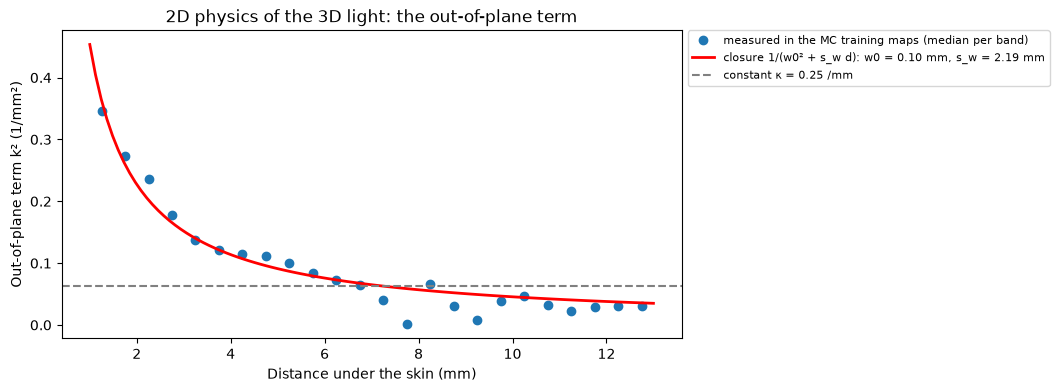

In [4]:
POOL = 8
depths, k2s, bc_values = [], [], []
for f in shot_frames:
    b = frame_tensors(f)
    D = diffusion_coefficient(b["mua"], b["musp"], b["tissue"])
    u_c, D_c, mua_c, d_c = (F.avg_pool2d(x, POOL) for x in (b["u_mc"], D, b["mua"], b["dist"]))
    inside = -F.max_pool2d(-b["tissue"].float(), POOL) > 0.5
    inside[..., :2, :] = inside[..., -2:, :] = False
    inside[..., :, :2] = inside[..., :, -2:] = False
    inside &= d_c > 1.0
    k2 = log_residual(u_c, D_c, mua_c, pixel_mm * POOL, 0.0) / D_c
    depths.append(d_c[inside].numpy()); k2s.append(k2[inside].numpy())
    skin = b["tissue"] & (b["dist"] < 1.5 * pixel_mm)
    skin[..., :2, :] = skin[..., -2:, :] = False
    skin[..., :, :2] = skin[..., :, -2:] = False
    bc_values.append((2 * physics["A"] * D * normal_derivative(b["u_mc"], b["dist"], pixel_mm))[skin].numpy())
depths, k2s = np.concatenate(depths), np.concatenate(k2s)
bands = [b for b in np.arange(1.0, 13.0, 0.5) if ((depths >= b) & (depths < b + 0.5)).sum() > 30]
centres = np.array(bands) + 0.25
medians = np.array([np.median(k2s[(depths >= b) & (depths < b + 0.5)]) for b in bands])
closure = lambda d, w0sq, s: 1.0 / (w0sq + s * d)
(w0sq, s_w), _ = curve_fit(closure, centres, medians, p0=[1.0, 2.0], bounds=([0.01, 0.01], [50, 50]))
pinn_cfg["closure_w0sq_start"], pinn_cfg["closure_s_start"] = float(w0sq), float(s_w)
pinn_cfg["bc_target"] = float(np.median(np.concatenate(bc_values)))
print(f"Closure fitted on the training shots: w0^2 = {w0sq:.3f} mm^2 (beam width at the skin {np.sqrt(w0sq):.2f} mm), s_w = {s_w:.2f} mm")
print(f"Boundary value 2AD du/dn of the MC fluence at the skin: b = {pinn_cfg['bc_target']:.3f} (purely diffuse light: 1)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(centres, medians, "o", label="measured in the MC training maps (median per band)")
dd = np.linspace(1, 13, 100)
ax.plot(dd, closure(dd, w0sq, s_w), "r-", lw=2, label=f"closure 1/(w0² + s_w d): w0 = {np.sqrt(w0sq):.2f} mm, s_w = {s_w:.2f} mm")
ax.axhline(0.25 ** 2, color="grey", ls="--", label="constant κ = 0.25 /mm")
ax.set_xlabel("Distance under the skin (mm)")
ax.set_ylabel("Out-of-plane term k² (1/mm²)")
ax.set_title("2D physics of the 3D light: the out-of-plane term")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
io_utils.save_figure(fig, "05_out_of_plane_closure")
plt.show()

Training helper functions

In [5]:
ckpt = io_utils.project_path("results", "checkpoints", "x").parent

def train(name, options=None, shots=None, seed=0):
    """Stage 1 (or load it from the cache). Returns the model and its info dict."""
    file = ckpt / f"{name}.pt"
    if file.exists():
        model = train_v2.make_model(cfg, pinn_cfg, options, device)
        model.load_state_dict(torch.load(file, map_location=device))
        return model, json.load(open(ckpt / f"{name}.json"))
    t0 = time.time()
    torch.cuda.reset_peak_memory_stats()
    model, history = train_v2.train_forward(data, shots or shot_frames, pool, cfg, pinn_cfg, physics, options, seed, device,
                                            progress_file=runs / f"progress_{name}.jsonl")
    end = history[-1]
    w0sq_learned, s_learned = model.closure_values()
    info = {"history": history, "minutes": (time.time() - t0) / 60, "w0sq": w0sq_learned, "s_w": s_learned,
            "tau_scale": torch.exp(model.log_tau_scale).item(), "peak_gpu_gb": torch.cuda.max_memory_allocated() / 1e9,
            "best_step": end["best_step"], "stopped_early": end["stopped_early"], "stop_reason": end["stop_reason"],
            "options": options or {}}
    torch.save(model.state_dict(), file)
    json.dump(info, open(ckpt / f"{name}.json", "w"))
    return model, info

def inverse(model, name, options=None, seed=0, prior_centre=None):
    """Stage 2 (or load the learned alpha and c from the cache). Sets them in the model."""
    file = ckpt / f"{name}_inverse.json"
    if file.exists():
        saved = json.load(open(file))
        model.alpha_raw.data = torch.tensor(saved["alpha_raw"], device=device)
        model.log_c.data = torch.tensor(saved["log_c"], device=device)
        return saved
    history = train_v2.fit_inverse(model, data, pool, pinn_cfg, region_mua, options, seed, device, prior_centre)
    saved = {"alpha": train_v2.learned_alpha(model), "alpha_raw": model.alpha_raw.tolist(),
             "log_c": model.log_c.item(), "history": history}
    json.dump(saved, open(file, "w"))
    return saved

def forward_phi(model, frames):
    """Fluence at the literature properties (alpha = 1), for comparison with Monte Carlo."""
    u = train_v2.predict(model, data, frames, device, literature=True)
    return dict(zip(frames, np.exp(u)))

def last_check(info):
    """MC loss on the 5 training frames and PDE loss on the unlabelled watch frames at the kept (best) state."""
    checks = [r for r in info["history"] if r.get("check")]
    kept = [r for r in checks if r["step"] == info["best_step"]] or checks[-1:]
    return kept[0]["mc_check"], kept[0]["pde_check"]

Deciding the Form of PDE

In [6]:
candidates = {}
for form in ["absolute", "differential"]:
    m, i = train(f"full_seed0_{form}", {"pde_form": form})
    mc_check, pde_check = last_check(i)
    candidates[form] = {"model": m, "info": i, "mc": mc_check, "diverged": "diverged" in i["stop_reason"] or "NaN" in i["stop_reason"]}
    print(f"{form:12s} PDE: training-frame MC loss {mc_check:.5f}   unlabelled-frame PDE loss {pde_check:.3f}   "
          f"best step {i['best_step']}   stopped early: {i['stop_reason'] or 'no'}   ({i['minutes']:.1f} min)")
allowed = [k for k in candidates if not candidates[k]["diverged"]] or list(candidates)
pde_form = min(allowed, key=lambda k: candidates[k]["mc"])
main_options = {"pde_form": pde_form}
print(f"\nKept: {pde_form} PDE")

# the main model: the same training with random seed 4 (the five seeds of section 9 were compared with the
# label-free health check only: MC loss on the 5 training frames and PDE loss on unlabelled frames)
main_name = "ensemble_seed4"
model, info = train(main_name, main_options, seed=4)
mc_check, pde_check = last_check(info)
print(f"Main model {main_name}: training-frame MC loss {mc_check:.5f}, unlabelled-frame PDE loss {pde_check:.3f}")

absolute     PDE: training-frame MC loss 0.00044   unlabelled-frame PDE loss 0.032   best step 4999   stopped early: no   (42.8 min)
differential PDE: training-frame MC loss 4.32132   unlabelled-frame PDE loss 485.027   best step 500   stopped early: diverged (MC loss 37.6735 > 3 x best 4.3213)   (12.8 min)

Kept: absolute PDE
Main model ensemble_seed4: training-frame MC loss 0.00045, unlabelled-frame PDE loss 0.020


Training curves

Training time: 42.6 min   peak GPU memory: 7.7 GB   best step 4999
learned closure: w0 = 0.115 mm, s_w = 2.148 mm   physics-layer scale s = 1.307


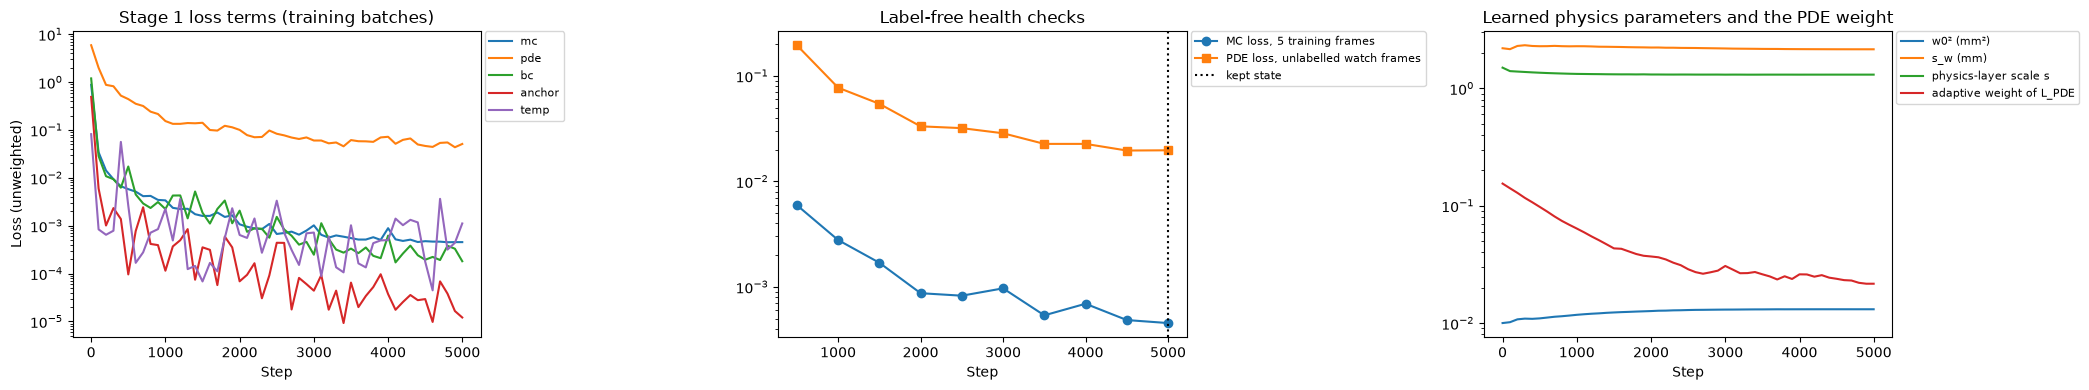

In [7]:
hist = pd.DataFrame([r for r in info["history"] if "total" in r])
checks = pd.DataFrame([r for r in info["history"] if r.get("check")])
print(f"Training time: {info['minutes']:.1f} min   peak GPU memory: {info['peak_gpu_gb']:.1f} GB   best step {info['best_step']}\n"
      f"learned closure: w0 = {np.sqrt(info['w0sq']):.3f} mm, s_w = {info['s_w']:.3f} mm   physics-layer scale s = {info['tau_scale']:.3f}")
fig, axes = plt.subplots(1, 3, figsize=(21, 4))
for c in ["mc", "pde", "bc", "anchor", "temp"]:
    if c in hist:
        axes[0].semilogy(hist["step"], hist[c], label=c)
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Loss (unweighted)")
axes[0].set_title("Stage 1 loss terms (training batches)")
axes[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
axes[1].semilogy(checks["step"], checks["mc_check"], "o-", label="MC loss, 5 training frames")
axes[1].semilogy(checks["step"], checks["pde_check"], "s-", label="PDE loss, unlabelled watch frames")
axes[1].axvline(info["best_step"], color="k", ls=":", label="kept state")
axes[1].set_xlabel("Step")
axes[1].set_title("Label-free health checks")
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
axes[2].plot(hist["step"], hist["w0sq"], label="w0² (mm²)")
axes[2].plot(hist["step"], hist["spread"], label="s_w (mm)")
axes[2].plot(hist["step"], hist["tau_scale"], label="physics-layer scale s")
axes[2].plot(hist["step"], hist["w_pde"], label="adaptive weight of L_PDE")
axes[2].set_yscale("log")
axes[2].set_xlabel("Step")
axes[2].set_title("Learned physics parameters and the PDE weight")
axes[2].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
plt.tight_layout()
io_utils.save_figure(fig, "05_training_curves_stage1")
plt.show()

Forward accuracy on the test block


In [8]:
def load_baseline(name):
    """A precomputed baseline fluence map (saved on the 0-1 scale of the 2x smaller grid) on the full grid."""
    baseline_scale = json.load(open(io_utils.project_path("v1_reference", "predictions", "physics.json")))["scale_01"]
    small = np.load(io_utils.project_path("v1_reference", "predictions", f"{name}.npy"), mmap_mode="r")
    return lambda f: correct.upsample_fluence(np.array(small[f]) * baseline_scale, (n_rows, n_cols))

phi_v2 = forward_phi(model, test_frames)
methods = {
    "1D exponential": load_baseline("phi_1d"),
    "2D diffusion, constant kappa (needs a solver)": load_baseline("phi_base_2d"),
    "PI-FluenceNet (3 maps only)": lambda f: phi_v2[f],
}
fwd_test = fluence_table(methods, test_frames)
fwd_test.to_csv(io_utils.project_path("results", "tables", "05_forward_accuracy_test.csv"), index=False)
print("Test block (frames 156–196):")
print(fwd_test.round(3).to_string(index=False))
breathing_test = [f for f in test_frames if f in flagged]
print(f"\nPI-FluenceNet on the {len(breathing_test)} breathing frames of the test block: "
      f"{np.mean([metrics.fluence_errors(phi_v2[f], phi_mc[f], eval_mask[f])['median_rel_error_%'] for f in breathing_test]):.2f} % median error")

Test block (frames 156–196):
                                        model  log10_rmse  mean_rel_error_%  median_rel_error_%  ssim_log  psnr_log_dB  median_rel_error_rescaled_%
                               1D exponential       0.341            87.836              54.106     0.937       21.641                       53.574
2D diffusion, constant kappa (needs a solver)       0.089            19.286              18.950     0.957       33.038                       20.706
                  PI-FluenceNet (3 maps only)       0.024             4.835               4.378     0.996       44.779                        4.105

PI-FluenceNet on the 12 breathing frames of the test block: 4.11 % median error


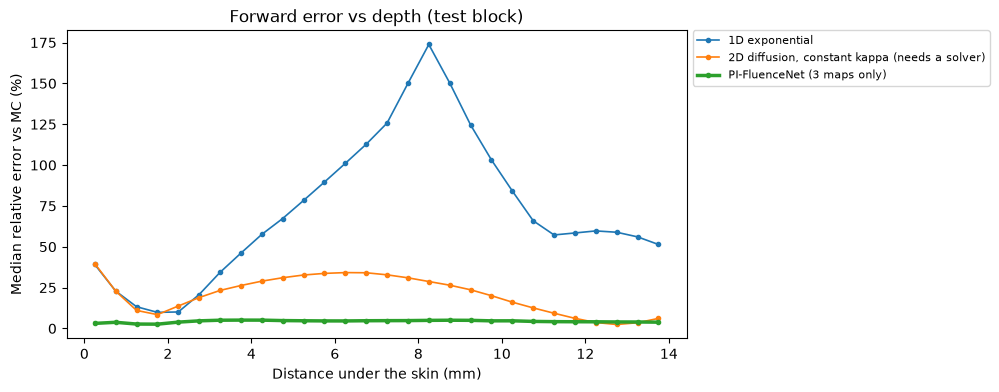

In [9]:
bins = np.arange(0, 14.5, 0.5)
fig, ax = plt.subplots(figsize=(8, 4))
for name, phi in methods.items():
    curves = [metrics.error_vs_depth(phi(f), phi_mc[f], eval_mask[f], dist[f], bins) for f in test_frames[::4]]
    ax.plot(bins[:-1] + 0.25, 100 * np.nanmean(curves, axis=0), "o-", ms=3, label=name, lw=2.5 if "PI-FluenceNet" in name else 1.2)
ax.set_xlabel("Distance under the skin (mm)")
ax.set_ylabel("Median relative error vs MC (%)")
ax.set_title("Forward error vs depth (test block)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
io_utils.save_figure(fig, "05_forward_error_vs_depth")
plt.show()

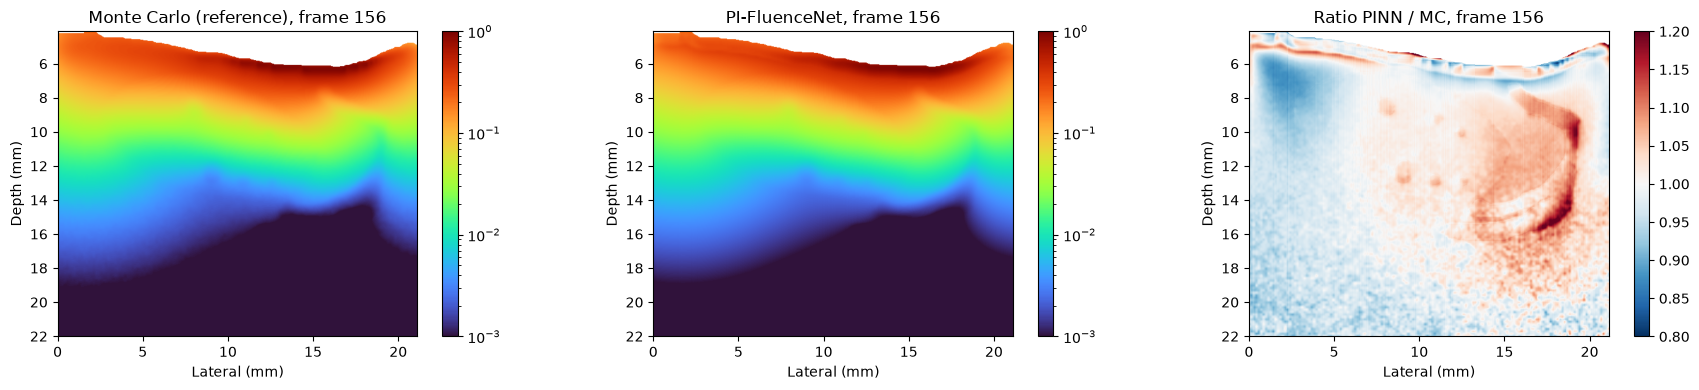

In [10]:
f = test_frames[0]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (title, img) in zip(axes, [("Monte Carlo (reference)", phi_mc[f]), ("PI-FluenceNet", phi_v2[f]),
                                   ("Ratio PINN / MC", phi_v2[f] / phi_mc[f])]):
    if title.startswith("Ratio"):
        im = ax.imshow(np.where(tissue[f], img, np.nan), cmap="RdBu_r", vmin=0.8, vmax=1.2, extent=extent)
    else:
        im = ax.imshow(np.where(tissue[f], to01(img), np.nan), cmap="turbo", norm=LogNorm(vmin=1e-3, vmax=1), extent=extent)
    plt.colorbar(im, ax=ax, fraction=0.035)
    ax.set_title(f"{title}, frame {f}")
    ax.set_xlabel("Lateral (mm)")
    ax.set_ylabel("Depth (mm)")
plt.tight_layout()
io_utils.save_figure(fig, "05_pinn_vs_mc")
plt.show()

Inference

In [11]:
from src import preprocess
f = test_frames[0]
torch.cuda.synchronize()
t0 = time.perf_counter()
for _ in range(10):
    frame_maps = optical_props.property_maps(class_maps[f], props, classes)
    d = preprocess.distance_into_tissue(class_maps[f], classes["coupling"], pixel_mm)
    one = {k: torch.as_tensor(v, dtype=torch.float32, device=device)[None, None] for k, v in frame_maps.items()}
    one.update({"dist": torch.as_tensor(d, device=device)[None, None],
                "class_map": torch.as_tensor(class_maps[f], device=device)[None, None],
                "tissue": torch.as_tensor((class_maps[f] > 0) & (d > 0), device=device)[None, None]})
    with torch.no_grad():
        u, _ = model(one, torch.zeros(1, len(TISSUES), device=device))
    torch.cuda.synchronize()
ms = (time.perf_counter() - t0) / 10 * 1000
same = np.allclose(np.exp(u[0, 0].cpu().numpy()), phi_v2[f], rtol=1e-3)
print(f"Segmentation -> fluence map: {ms:.0f} ms per frame (Monte Carlo: 33,000 ms; 2D solver: 900 ms). Same result as above: {same}")

Segmentation -> fluence map: 26 ms per frame (Monte Carlo: 33,000 ms; 2D solver: 900 ms). Same result as above: True


Stage 2: learn the tissue absorption scales α from the PA images

Learned alpha: {'skin': 0.836, 'soft_tissue': 1.028, 'cortex': 0.745, 'medulla': 1.118, 'vessel': 0.967}


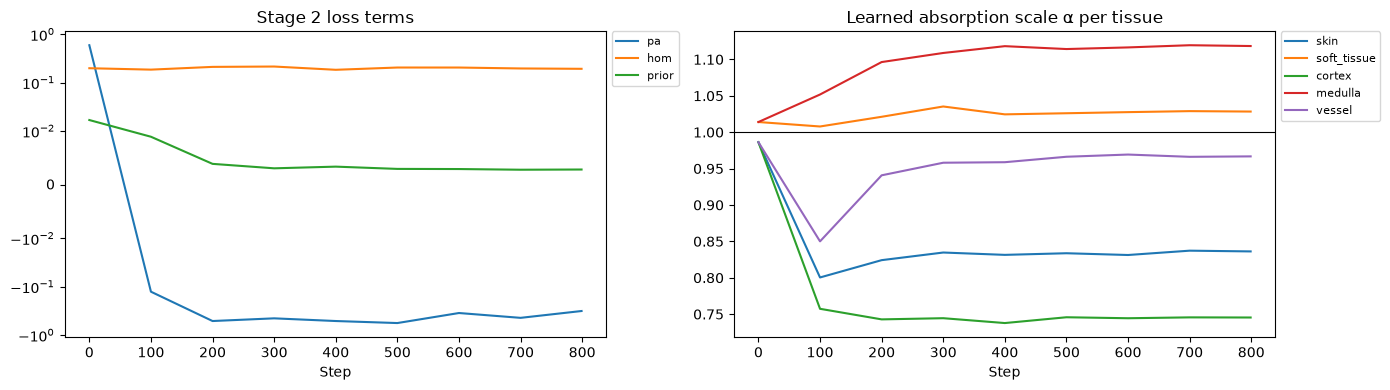

In [12]:
inv = inverse(model, main_name)
print("Learned alpha:", {k: round(v, 3) for k, v in inv["alpha"].items()})
ih = pd.DataFrame(inv["history"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for c in ["pa", "hom", "prior"]:
    axes[0].plot(ih["step"], ih[c], label=c)
axes[0].set_yscale("symlog", linthresh=1e-2)       # the censored PA loss is a negative log-likelihood and can be < 0
axes[0].set_title("Stage 2 loss terms")
axes[0].set_xlabel("Step")
axes[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
for n in TISSUES:
    axes[1].plot(ih["step"], ih[f"alpha_{n}"], label=n)
axes[1].axhline(1, color="k", lw=0.8)
axes[1].set_title("Learned absorption scale α per tissue")
axes[1].set_xlabel("Step")
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
plt.tight_layout()
io_utils.save_figure(fig, "05_training_curves_stage2")
plt.show()

Model analysis

In [13]:
rng = np.random.default_rng(42)
members = [model]
alphas = [inv["alpha"]]
names = [main_name]
for s in range(0, 4):
    centre = None if s == 0 else rng.normal(0.0, 0.2, size=len(TISSUES)).tolist()
    name = f"full_seed0_{pde_form}" if s == 0 else f"ensemble_seed{s}"
    m, i = train(name, main_options, seed=s)
    print(f"seed {s}: {i['minutes']:.1f} min, best step {i['best_step']}, stopped early: {i['stop_reason'] or 'no'}")
    alphas.append(inverse(m, name, prior_centre=centre, seed=s)["alpha"])
    members.append(m)
    names.append(name)

alpha_df = pd.DataFrame(alphas, index=names)
alpha_df.loc["mean"] = alpha_df.mean()
alpha_df.loc["std"] = alpha_df.iloc[:-1].std()
alpha_df.to_csv(io_utils.project_path("results", "tables", "05_alpha_ensemble.csv"))
print(alpha_df.round(3))

seed 0: 42.8 min, best step 4999, stopped early: no
seed 1: 42.7 min, best step 4999, stopped early: no
seed 2: 42.6 min, best step 4999, stopped early: no
seed 3: 42.6 min, best step 4999, stopped early: no
                      skin  soft_tissue  cortex  medulla  vessel
ensemble_seed4       0.836        1.028   0.745    1.118   0.967
full_seed0_absolute  0.990        0.945   0.889    0.951   0.968
ensemble_seed1       1.048        0.769   1.017    1.126   0.657
ensemble_seed2       0.764        0.971   0.836    0.939   0.813
ensemble_seed3       1.176        1.107   0.902    1.172   1.072
mean                 0.963        0.964   0.878    1.061   0.895
std                  0.165        0.126   0.099    0.108   0.162


In [14]:
pred_dir = io_utils.project_path("data", "predictions", "x").parent
all_frames = list(range(n_frames))
phi_sum, phi_sq = np.zeros(class_maps.shape, np.float64), np.zeros(class_maps.shape, np.float64)
for m in members:
    phi = np.exp(train_v2.predict(m, data, all_frames, device))      # learned alpha
    phi_sum += phi
    phi_sq += phi ** 2
phi_mean = (phi_sum / len(members)).astype(np.float32)
phi_std = np.sqrt(np.maximum(phi_sq / len(members) - phi_mean ** 2, 0)).astype(np.float32)
rel_unc = phi_std / phi_mean
print(f"Relative fluence uncertainty in tissue: median {100 * np.median(rel_unc[tissue]):.1f} %, 95th percentile {100 * np.percentile(rel_unc[tissue], 95):.1f} %")
phi_forward_all = np.exp(train_v2.predict(model, data, all_frames, device, literature=True)).astype(np.float32)
phi_main = np.exp(train_v2.predict(model, data, all_frames, device)).astype(np.float32)
np.save(pred_dir / "phi_pinn.npy", phi_main)                  # main model: normalised fluence (1 under the skin), learned alpha
np.save(pred_dir / "phi_pinn_ensemble.npy", phi_mean)         # mean of the 5 models
np.save(pred_dir / "phi_pinn_std.npy", phi_std)
np.save(pred_dir / "phi_pinn_forward.npy", phi_forward_all)   # literature properties
del phi_sum, phi_sq

Relative fluence uncertainty in tissue: median 11.5 %, 95th percentile 32.8 %


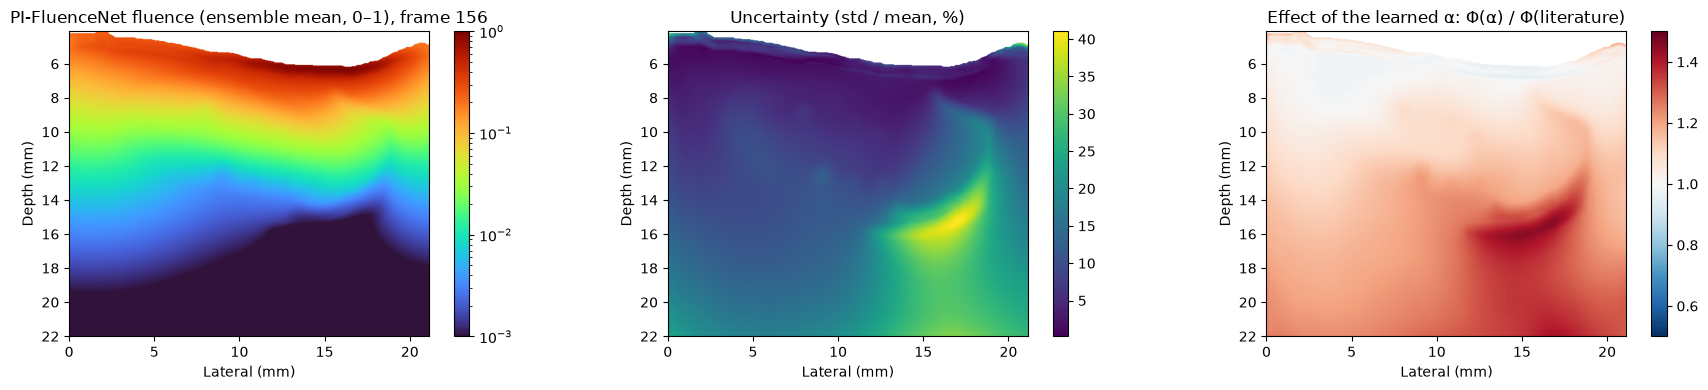

In [ ]:
f = test_frames[0]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
im = axes[0].imshow(np.where(tissue[f], to01(phi_mean[f]), np.nan), cmap="turbo", norm=LogNorm(vmin=1e-3, vmax=1), extent=extent)
axes[0].set_title(f"PI-FluenceNet fluence (ensemble mean, 0–1), frame {f}")
plt.colorbar(im, ax=axes[0], fraction=0.035)

im = axes[1].imshow(np.where(tissue[f], 100 * rel_unc[f], np.nan), cmap="viridis", extent=extent)
axes[1].set_title("Uncertainty (std / mean, %)")
plt.colorbar(im, ax=axes[1], fraction=0.035)

im = axes[2].imshow(np.where(tissue[f], phi_mean[f] / phi_forward_all[f], np.nan), cmap="RdBu_r", vmin=0.5, vmax=1.5, extent=extent)
axes[2].set_title("Effect of the learned α: Φ(α) / Φ(literature)")
plt.colorbar(im, ax=axes[2], fraction=0.035)

for ax in axes:
    ax.set_xlabel("Lateral (mm)")
    ax.set_ylabel("Depth (mm)")
plt.tight_layout()

io_utils.save_figure(fig, "05_pinn_fluence_uncertainty")
plt.show()

Save

In [16]:
w0sq_final, s_final = model.closure_values()
with open(pred_dir / "physics.json", "w") as fh:
    json.dump({"A": physics["A"], "scale_01": scale_01, "pde_form": pde_form, "main_name": main_name,
               "tau_sigma_mm": pinn_cfg["tau_sigma_mm"], "tau_scale_start": pinn_cfg["tau_scale_start"],
               "tau_scale": torch.exp(model.log_tau_scale).item(),
               "closure_w0sq_start": pinn_cfg["closure_w0sq_start"], "closure_s_start": pinn_cfg["closure_s_start"],
               "closure_w0sq": w0sq_final, "closure_s": s_final, "bc_target": pinn_cfg["bc_target"],
               "alpha_main": inv["alpha"], "alpha_mean": alpha_df.loc["mean"].to_dict(), "alpha_std": alpha_df.loc["std"].to_dict(),
               "inference_ms": ms}, fh, indent=1)
print("Saved:", sorted(p.name for p in pred_dir.glob("*")))

Saved: ['display.json', 'gain_v2.npy', 'pa_corrected_v2.npy', 'phi_pinn.npy', 'phi_pinn_ensemble.npy', 'phi_pinn_forward.npy', 'phi_pinn_std.npy', 'physics.json']
